In [1]:
import pandas as pd
import numpy as np
import pickle
import SimpleITK as sitk
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions
import torch
import torch.nn as nn
import torch.optim as optim
import random
from tqdm import tqdm
import torch.nn.functional as F
from torch.optim import lr_scheduler
import time

In [2]:
df_layers = pd.read_excel('../SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
df_layers

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,2.028292,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp,0.625221,1.992551,1.765525,0.930700,0.678581,1.968629,1.024268,0.953173,1.600363,0.961477,...,0.000000,0.000000,0.0,0.000000,0.0,0.861023,0,0,0,0.875238
MOs,1.417198,1.381516,1.645074,0.670320,2.725806,0.853611,1.209884,1.446972,0.000000,0.000000,...,0.000000,1.621683,0.0,0.000000,0.0,0.768877,0,0,0,0.000000
SSp-n,0.000000,0.789537,1.283165,1.795210,1.301726,0.000000,1.947067,2.399795,0.000000,1.158404,...,0.000000,0.000000,0.0,0.000000,0.0,0.810396,0,0,0,0.000000
SSp-bfd,0.000000,1.159698,0.766737,1.669994,1.934520,0.447926,1.166723,0.869816,3.467967,1.047941,...,0.000000,0.000000,0.0,0.000000,0.0,0.191446,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.514522,2.131420,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


## 1. Stage2

In [3]:
with open('../brain_region_wo_layer_stage2.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([1.32295741e-06, 2.22448016e-06, 4.46894026e-06, ...,
         9.99998459e-01, 9.99998823e-01, 1.00000000e+00]),
  'spike_voltages': array([1.02225975e-04, 1.90227904e-04, 6.86466592e-05, ...,
         1.46565464e-04, 1.36938193e-04, 8.16656393e-05])},
 'LGd': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([1.15912066e-04, 2.21375594e-04, 2.84903537e-04, ...,
         7.53099230e-05, 1.34822039e-04, 6.84298866e-05])},
 'CEA': {'spike_times': array([9.88512933e-07, 3.90553693e-06, 7.73567368e-06, ...,
         9.99995064e-01, 9.99997947e-01, 9.99999048e-01]),
  'spike_voltages': array([2.71024008e-04, 1.77588983e-04, 8.60513755e-05, ...,
         1.29396503e-04, 9.81526682e-05, 5.01546710e-05])},
 'VPM': {'spike_times': array([4.29821969e-10, 5.48716916e-10, 1.60778299e-09, ...,
         1.00000000e+00, 1.00000000e+00, 1.00000000e+00]),
  'spike_voltages': array([0.00018025, 0.00016094, 0.00014604, ..., 0.00022785, 0.00015073

In [4]:
len(C_traces)

89

In [5]:
keys = list(C_traces.keys())

df_filtered = df_layers.loc[df_layers.index.intersection(keys), df_layers.columns.intersection(keys)]
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_filtered),
    index=df_filtered.index,
    columns=df_filtered.columns
)
df_scaled

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,LD,MD,SMT,PVT,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,0.614604,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp,0.441167,0.378662,0.534982,0.281224,0.237631,0.211517,0.242158,0.083040,0.402819,0.297850,...,0.096450,0.000000,0.000000,0.0,0.0,0.372428,0.0,0.0,0.0,0.720896
MOs,1.000000,0.262542,0.498483,0.202547,0.954544,0.091715,0.286042,0.126060,0.000000,0.000000,...,0.000000,0.000000,0.208482,0.0,0.0,0.332571,0.0,0.0,0.0,0.000000
SSp-n,0.000000,0.150043,0.388819,0.542448,0.455849,0.000000,0.460327,0.209069,0.000000,0.358855,...,0.040574,0.000000,0.000000,0.0,0.0,0.350530,0.0,0.0,0.0,0.000000
SSp-bfd,0.000000,0.220388,0.232333,0.504613,0.677445,0.048127,0.275838,0.075778,0.872903,0.324635,...,0.597337,0.000000,0.000000,0.0,0.0,0.082808,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.477782,0.274014,0.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


In [6]:
#df_scaled.to_csv("./result/wo_layer/stage1/df_scaled.csv", index=True)

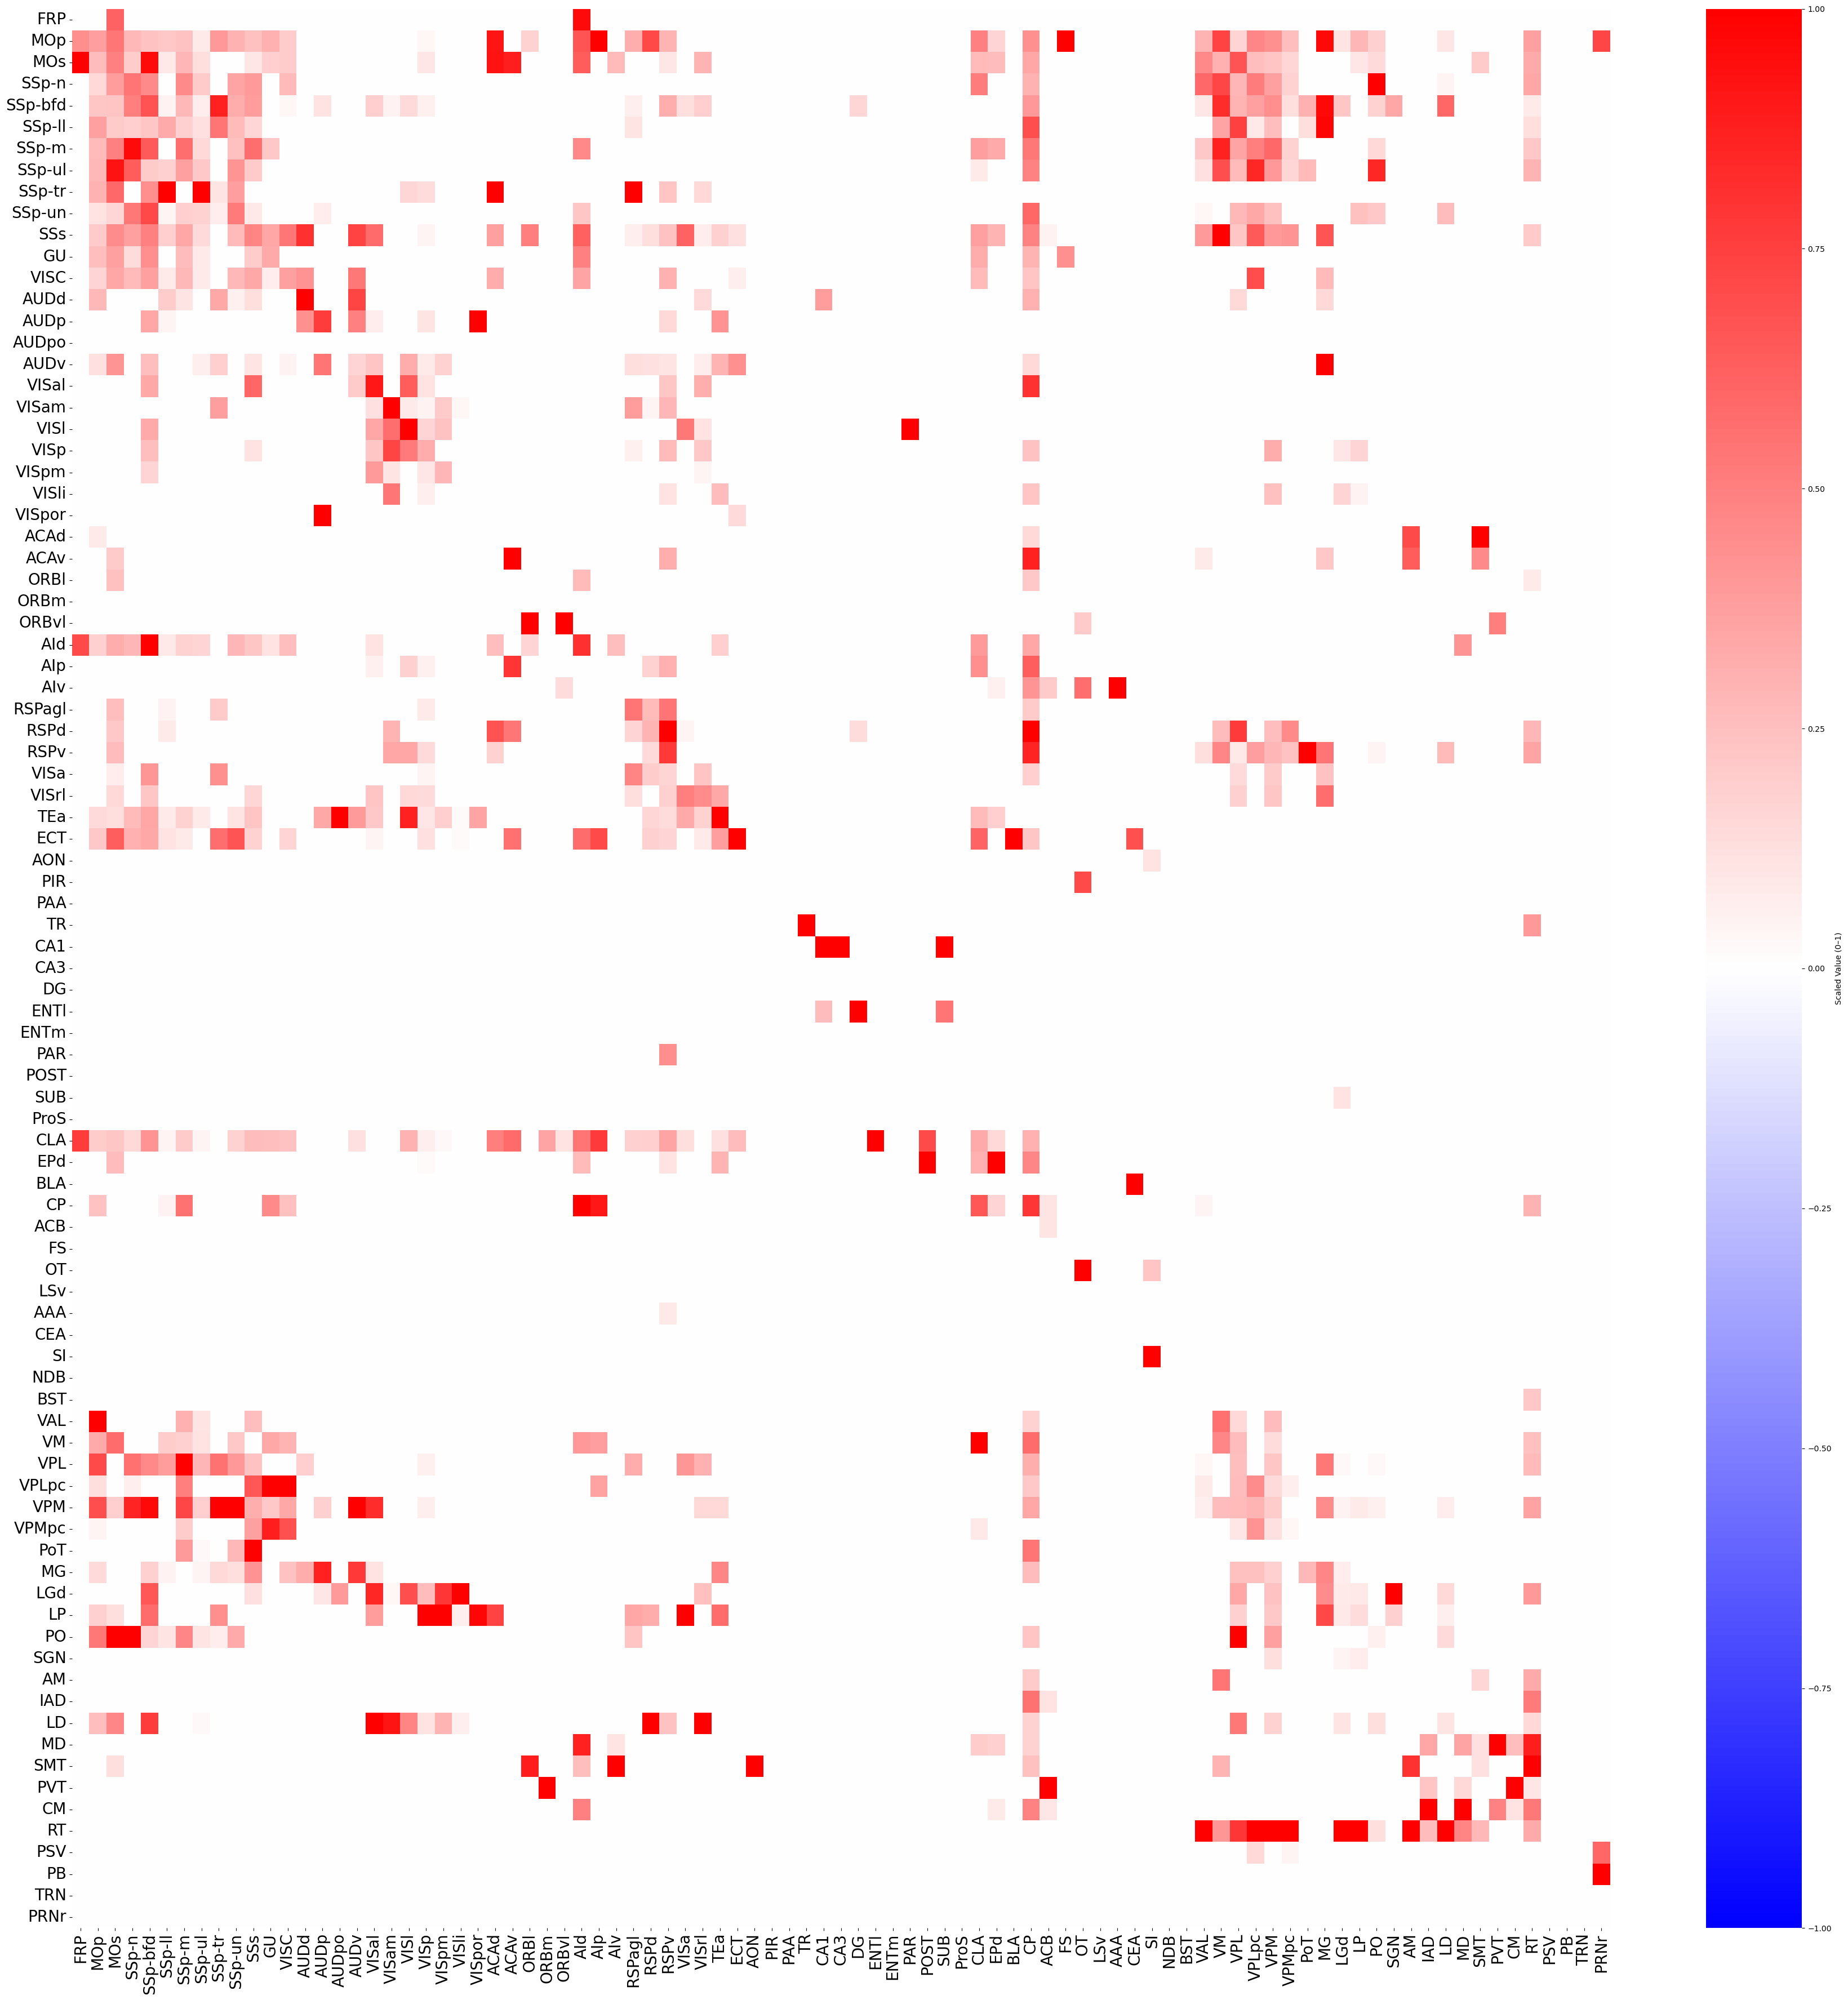

In [7]:
plt.figure(figsize=(max(10, len(df_scaled.columns) * 0.4),
                    max(8, len(df_scaled.index) * 0.4)))

ax = sns.heatmap(df_scaled, cmap='bwr', cbar_kws={'label': 'Scaled Value (0–1)'}, 
                 xticklabels=True, yticklabels=True,vmin=-1,vmax=1)

ax.set_xticks([x + 0.5 for x in range(len(df_scaled.columns))])
ax.set_xticklabels(df_scaled.columns, rotation=90, fontsize=20)

ax.set_yticks([y + 0.5 for y in range(len(df_scaled.index))])
ax.set_yticklabels(df_scaled.index, rotation=0, fontsize=20)

plt.title("", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
import numpy as np


def build_region_binned_traces_nan(
    aligned_region_data,
    dt=0.01,
    duration_mode="percentile",
    duration_percentile=100,
    convert_to_rate=False,
    rescale=True
):

    if dt <= 0:
        raise ValueError("dt must be greater than 0")

    end_times = []

    for _, data in aligned_region_data.items():

        spike_times = np.asarray(
            data.get("spike_times", []),
            dtype=float
        )

        spike_times = spike_times[
            np.isfinite(spike_times)
        ]

        if spike_times.size == 0:
            end_times.append(0.0)
        else:
            end_times.append(
                float(np.max(spike_times))
            )

    valid_end_times = np.asarray(end_times)
    valid_end_times = valid_end_times[
        valid_end_times > 0
    ]

    if valid_end_times.size == 0:
        raise ValueError(
            "No valid spike times found."
        )

    if duration_mode == "min":
        used_duration = np.min(valid_end_times)

    elif duration_mode == "median":
        used_duration = np.median(valid_end_times)

    elif duration_mode == "percentile":
        used_duration = np.percentile(
            valid_end_times,
            duration_percentile
        )

    elif duration_mode == "max":
        used_duration = np.max(valid_end_times)

    else:
        raise ValueError(
            "duration_mode must be "
            "'min', 'median', 'percentile', or 'max'"
        )

    n_bins = int(np.ceil(used_duration / dt))

    edges = np.arange(
        n_bins + 1,
        dtype=float
    ) * dt

    centers = (
        edges[:-1] +
        edges[1:]
    ) / 2

    binned = {}

    for rid, data in aligned_region_data.items():

        spike_times = np.asarray(
            data.get("spike_times", []),
            dtype=float
        )

        spike_times = spike_times[
            np.isfinite(spike_times)
        ]

        if spike_times.size == 0:

            binned[rid] = np.full(
                n_bins,
                np.nan,
                dtype=float
            )

            continue

        spike_times = spike_times[
            (spike_times >= 0) &
            (spike_times < used_duration)
        ]

        spike_counts, _ = np.histogram(
            spike_times,
            bins=edges
        )

        region_trace = spike_counts.astype(float)

        if convert_to_rate:
            region_trace /= dt

        if rescale:

            mn = region_trace.min()
            mx = region_trace.max()

            if mx > mn:
                region_trace = (
                    region_trace - mn
                ) / (mx - mn)
            else:
                region_trace = np.zeros_like(
                    region_trace,
                    dtype=float
                )

        binned[rid] = region_trace

    return centers, binned, used_duration


#################################################
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)

In [9]:
import os
import math
import random
import numpy as np
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler


# ----------------- Seed -----------------
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False


# ----------------- Transformer utils -----------------
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 4096):
        super().__init__()
        pe = torch.zeros(max_len, d_model)  # (max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, T, D)
        T = x.size(1)
        return x + self.pe[:T, :].unsqueeze(0).to(dtype=x.dtype, device=x.device)


def make_causal_mask(T: int, device: torch.device) -> torch.Tensor:
    # True means "mask out"
    return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)


class TemporalTransformerEncoder(nn.Module):
    def __init__(
        self,
        in_dim: int,
        d_model: int = 32,
        nhead: int = 4,
        num_layers: int = 2,
        dropout: float = 0.3,
        max_len: int = 4096,
        causal: bool = True,
    ):
        super().__init__()
        self.in_proj = nn.Linear(in_dim, d_model)
        self.pos_enc = SinusoidalPositionalEncoding(d_model, max_len=max_len)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=4 * d_model,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.causal = causal

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, T, in_dim)
        x = self.in_proj(x)      # (B, T, d_model)
        x = self.pos_enc(x)
        x = self.dropout(x)
        mask = None
        if self.causal:
            T = x.size(1)
            mask = make_causal_mask(T, x.device)  # (T, T), bool
        out = self.encoder(x, mask=mask)          # (B, T, d_model)
        return out


# ----------------- Graph-learning -----------------
class SimpleGraphLearn(nn.Module):
    def __init__(self, node_dim, nodes, dropout=0.5, struct_connectome=None):
        super().__init__()
        self.nodes = nodes
        self.dropout = dropout

        self.gate_net = nn.Sequential(
            nn.Linear(node_dim * 2, node_dim),
            nn.Sigmoid()
        )

        # NOTE: self.attention exists in your original code but was unused; removed for clarity.
        self.norm = nn.LayerNorm(nodes)

        # per-node modulation (N, D)
        self.w = nn.Parameter(torch.empty(nodes, node_dim))
        nn.init.xavier_uniform_(self.w, gain=1.414)

        if struct_connectome is not None:
            sc = torch.as_tensor(struct_connectome, dtype=torch.float32)
            self.register_buffer("struct_connectome", sc, persistent=True)
        else:
            self.struct_connectome = None

        self.graph_weight = nn.Parameter(torch.ones(1))
        self.struct_weight = nn.Parameter(torch.ones(1))

    def forward(self, node_features, temporal_features=None):
        # node_features: (B, N, D)
        B, N, D = node_features.shape

        if temporal_features is not None:
            # temporal_features: (B, N, D)
            concat_features = torch.cat([node_features, temporal_features], dim=-1)  # (B, N, 2D)
            gate = self.gate_net(concat_features)                                   # (B, N, D)
            node_features = gate * node_features + (1.0 - gate) * temporal_features

        # node-wise modulation + residual
        node_res = node_features * self.w.unsqueeze(0) + node_features             # (B, N, D)

        # skip attention (B, N, N)
        skip_atten = torch.matmul(node_res, node_res.transpose(-2, -1))
        skip_atten = self.norm(skip_atten)

        # dot-product similarity (attention-like) (B, N, N)
        attention_scores = torch.matmul(node_features, node_features.transpose(-2, -1))
        attention_scores = attention_scores / (D ** 0.5)
        attention_scores = F.dropout(attention_scores, self.dropout, training=self.training)

        adj_raw = attention_scores + skip_atten  # (B, N, N)

        if self.struct_connectome is not None:
            struct_adj = self.struct_connectome.unsqueeze(0).expand(B, -1, -1).to(adj_raw.device)
            adj = self.graph_weight * adj_raw + self.struct_weight * struct_adj
        else:
            adj = adj_raw

        adj = torch.tanh(adj)

        if self.struct_connectome is not None:
            ub = self.struct_connectome.unsqueeze(0).expand(B, -1, -1).to(adj.device)
            adj = torch.clamp(adj, -ub, ub)

        return adj


# ----------------- Temporal dynamic graph learning model -----------------
class TimeSeriesDynamicGraphModel(nn.Module):
    def __init__(
        self,
        device,
        num_nodes,
        seq_length=12,
        in_dim=1,
        out_dim=1,
        hidden_dim=32,
        dropout=0.3,
        embed_dim=10,
        struct_connectome=None,
        temporal_encoder_type="lstm",  # "lstm" or "transformer"
        transformer_num_layers=2,
        transformer_nhead=4,
        transformer_d_model=32,        # typically == hidden_dim
        transformer_causal=True,
    ):
        super().__init__()
        self.device = device
        self.num_nodes = num_nodes
        self.seq_length = seq_length
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.temporal_encoder_type = temporal_encoder_type

        self.node_embedding = nn.Embedding(num_nodes, embed_dim)
        self.temporal_fusion = nn.Linear(hidden_dim, embed_dim)

        self.graph_learn = SimpleGraphLearn(
            node_dim=embed_dim,
            nodes=num_nodes,
            dropout=dropout,
            struct_connectome=struct_connectome
        )

        if temporal_encoder_type == "lstm":
            self.temporal_encoder = nn.LSTM(
                input_size=in_dim,
                hidden_size=hidden_dim,
                num_layers=2,
                batch_first=True,
                dropout=dropout
            )
        elif temporal_encoder_type == "transformer":
            if transformer_d_model != hidden_dim:
                raise ValueError(f"transformer_d_model ({transformer_d_model}) must equal hidden_dim ({hidden_dim}) "
                                 f"to keep downstream shapes unchanged.")
            self.temporal_encoder = TemporalTransformerEncoder(
                in_dim=in_dim,
                d_model=transformer_d_model,
                nhead=transformer_nhead,
                num_layers=transformer_num_layers,
                dropout=dropout,
                max_len=seq_length,
                causal=transformer_causal,
            )
        else:
            raise ValueError(f"Unknown temporal_encoder_type: {temporal_encoder_type}")

        self.gcn_layers = nn.ModuleList([nn.Linear(hidden_dim, hidden_dim) for _ in range(2)])

        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, input, pred_time_embed=None):
        # input: (B, T, N, in_dim)
        B, T, N, in_dim = input.shape
        assert N == self.num_nodes and T == self.seq_length, "Input shape mismatch."

        idx = torch.arange(N, device=self.device)
        node_embeddings = self.node_embedding(idx).unsqueeze(0).expand(B, -1, -1)  # (B, N, embed_dim)

        # per-node temporal encoding
        x_reshaped = input.permute(0, 2, 1, 3).contiguous().view(B * N, T, in_dim)  # (B*N, T, in_dim)

        if self.temporal_encoder_type == "lstm":
            temporal_out, _ = self.temporal_encoder(x_reshaped)                     # (B*N, T, hidden_dim)
        else:
            temporal_out = self.temporal_encoder(x_reshaped)                        # (B*N, T, hidden_dim)

        temporal_features = temporal_out.view(B, N, T, -1)                          # (B, N, T, hidden_dim)

        dynamic_graphs = []
        temporal_hiddens = []

        for t in range(T):
            h_t = temporal_features[:, :, t, :]                                     # (B, N, hidden_dim)
            h_proj_t = self.temporal_fusion(h_t)                                    # (B, N, embed_dim)

            adj_t = self.graph_learn(node_embeddings, h_proj_t)                     # (B, N, N)
            dynamic_graphs.append(adj_t)
            temporal_hiddens.append(h_t)

        adj_dynamic_all = torch.stack(dynamic_graphs, dim=1)                        # (B, T, N, N)

        # GCN over learned adjacency at each t
        gcn_outputs_all = []
        for t in range(T):
            current_h = temporal_hiddens[t]                                         # (B, N, hidden_dim)
            adj_t = dynamic_graphs[t]                                               # (B, N, N)

            for gcn_layer in self.gcn_layers:
                h_gcn = torch.matmul(adj_t.transpose(-1, -2), current_h)
                h_gcn = gcn_layer(h_gcn)
                h_gcn = F.relu(h_gcn)
                h_gcn = F.dropout(h_gcn, self.dropout, training=self.training)
                current_h = h_gcn

            gcn_outputs_all.append(current_h)

        gcn_outputs_all = torch.stack(gcn_outputs_all, dim=1)                       # (B, T, N, hidden_dim)

        final_hidden = gcn_outputs_all[:, -1, :, :]                                 # (B, N, hidden_dim)
        output = self.output_layer(final_hidden)                                    # (B, N, out_dim)

        return output, None, adj_dynamic_all


# ----------------- Trainer -----------------
class trainer:
    def __init__(
        self,
        num_nodes, seq_length, in_dim, out_dim,
        hidden_dim, dropout, lrate, wdecay, device,
        embed_dim,
        struct_connectome=None,
        struct_constraint_weight=0.2,
        temporal_encoder_type="lstm",
        transformer_num_layers=2,
        transformer_nhead=4,
        transformer_d_model=32,
        transformer_causal=True,
    ):
        self.model = TimeSeriesDynamicGraphModel(
            device=device,
            num_nodes=num_nodes,
            seq_length=seq_length,
            in_dim=in_dim,
            out_dim=out_dim,
            hidden_dim=hidden_dim,
            dropout=dropout,
            embed_dim=embed_dim,
            struct_connectome=struct_connectome,
            temporal_encoder_type=temporal_encoder_type,
            transformer_num_layers=transformer_num_layers,
            transformer_nhead=transformer_nhead,
            transformer_d_model=transformer_d_model,
            transformer_causal=transformer_causal,
        ).to(device)

        self.optimizer = optim.Adam(self.model.parameters(), lr=lrate, weight_decay=wdecay)
        self.scheduler = lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10, eps=1e-5, cooldown=20, verbose=True
        )

        self.loss = nn.MSELoss()
        self.clip = 0.5
        self.struct_constraint_weight = struct_constraint_weight

    def train(self, input, real_val):
        self.model.train()
        output, _, adj_d = self.model(input)
        loss = self.loss(output, real_val)

        # structural constraint on avg adjacency magnitude
        if getattr(self.model.graph_learn, "struct_connectome", None) is not None:
            # adj_d: (B, T, N, N)
            avg_adj = torch.mean(adj_d, dim=(0, 1))       # (N, N)
            struct_adj = self.model.graph_learn.struct_connectome.to(avg_adj.device)
            struct_loss = F.mse_loss(torch.abs(avg_adj), struct_adj)
            loss = loss + self.struct_constraint_weight * struct_loss

        loss.backward()
        if self.clip is not None:
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.clip)

        self.optimizer.step()
        self.optimizer.zero_grad()
        return loss.item()

    def eval(self, input, real_val):
        self.model.eval()
        with torch.no_grad():
            output, _, adj_d = self.model(input)
            loss = self.loss(output, real_val)
        return loss.item(), output, adj_d


# ----------------- Main training function -----------------
def train_timeseries_dynamic_graph(
    cell_trace,
    struct_connectome,
    seq_length,
    pred_length,
    hidden_dim,
    lr,
    epochs,
    batch_size,
    dropout,
    device=None,
    seed=42,
    val_ratio=0.2,
    patience=200,
    embed_dim=10,
    struct_constraint_weight=0.5,
    save_dir="./results/wo_layer/stage1",
    temporal_encoder_type="lstm",     # "lstm" or "transformer"
    transformer_num_layers=2,
    transformer_nhead=4,
    transformer_d_model=32,
    transformer_causal=True,
):
    set_seed(seed)
    os.makedirs(save_dir, exist_ok=True)

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    num_regions, total_time = cell_trace.shape
    if seq_length is None:
        seq_length = total_time - pred_length

    # ------------------ Data input ------------------
    data, targets = [], []
    cell_trace_norm = (cell_trace - np.mean(cell_trace)) / (np.std(cell_trace) + 1e-8)

    for t in range(total_time - seq_length - pred_length + 1):
        x = cell_trace_norm[:, t:t + seq_length].T.reshape(seq_length, num_regions, 1)          # (T, N, 1)
        y = cell_trace_norm[:, t + seq_length:t + seq_length + pred_length].T.reshape(num_regions, pred_length)  # (N, P)
        data.append(x)
        targets.append(y)

    data = np.asarray(data)       # (samples, T, N, 1)
    targets = np.asarray(targets) # (samples, N, P)

    split = int(len(data) * (1 - val_ratio))
    train_data = torch.FloatTensor(data[:split]).to(device)
    train_targets = torch.FloatTensor(targets[:split]).to(device)
    val_data = torch.FloatTensor(data[split:]).to(device)
    val_targets = torch.FloatTensor(targets[split:]).to(device)

    # ------------------ Model ------------------
    engine = trainer(
        num_nodes=num_regions,
        seq_length=seq_length,
        in_dim=1,
        out_dim=pred_length,
        hidden_dim=hidden_dim,
        dropout=dropout,
        lrate=lr,
        wdecay=0.0,
        device=device,
        embed_dim=embed_dim,
        struct_connectome=struct_connectome,
        struct_constraint_weight=struct_constraint_weight,
        temporal_encoder_type=temporal_encoder_type,
        transformer_num_layers=transformer_num_layers,
        transformer_nhead=transformer_nhead,
        transformer_d_model=transformer_d_model,
        transformer_causal=transformer_causal,
    )

    best_val = float('inf')
    patience_count = 0
    train_losses, val_losses = [], []
    epoch_avg_graphs = []

    print(f"Training start | encoder={temporal_encoder_type} | seq={seq_length}, T={total_time}")

    # ------------------ Train ------------------
    for epoch in range(epochs):
        train_loss = 0.0
        engine.model.train()

        for i in range(0, len(train_data), batch_size):
            train_loss += engine.train(train_data[i:i + batch_size], train_targets[i:i + batch_size])

        train_loss /= (len(train_data) // batch_size + 1)
        train_losses.append(train_loss)

        # -------- Validation --------
        engine.model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for i in range(0, len(val_data), batch_size):
                val_loss += engine.eval(val_data[i:i + batch_size], val_targets[i:i + batch_size])[0]

        val_loss /= (len(val_data) // batch_size + 1)
        val_losses.append(val_loss)
        engine.scheduler.step(val_loss)

        # ---- Save best ----
        if val_loss < best_val:
            best_val = val_loss
            patience_count = 0
            torch.save(engine.model.state_dict(), f"{save_dir}/best_model.pth")
        else:
            patience_count += 1

        if patience_count >= patience:
            print(f"Early stop @ epoch {epoch + 1}")
            break

        # ---- collect epoch avg graph ----
        with torch.no_grad():
            x = train_data[0:1]
            _, _, adj = engine.model(x)  # (1, T, N, N)
            epoch_avg_graphs.append(np.mean(adj.squeeze(0).cpu().numpy(), axis=0))  # avg over time -> (N, N)

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1}/{epochs} | Train {train_loss:.5f} | Val {val_loss:.5f}")

    print("Training done, loading best model")
    engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth", map_location=device))
    engine.model.eval()

    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))
    np.save(f"{save_dir}/epoch_avg_graphs.npy", np.array(epoch_avg_graphs))
    print(f"Saved epoch_avg_graphs.npy to {save_dir}")

    # ------------------ Full time inference ------------------
    print("Reconstructing full dynamic graph...")

    full_dynamic_graphs = np.zeros((total_time, num_regions, num_regions), dtype=np.float32)
    frame_count = np.zeros(total_time, dtype=np.float32)

    with torch.no_grad():
        for t in tqdm(range(total_time - seq_length + 1)):
            x = cell_trace_norm[:, t:t + seq_length].T.reshape(1, seq_length, num_regions, 1)
            x = torch.FloatTensor(x).to(device)

            _, _, adj_seq = engine.model(x)  # (1, T, N, N)
            adj_seq = adj_seq.squeeze(0).cpu().numpy()  # (T, N, N)

            for k in range(seq_length):
                idx = t + k
                full_dynamic_graphs[idx] += adj_seq[k]
                frame_count[idx] += 1.0

    for i in range(total_time):
        if frame_count[i] > 0:
            full_dynamic_graphs[i] /= frame_count[i]

    np.save(f"{save_dir}/dynamic_full_graphs.npy", full_dynamic_graphs)
    print(f"Saved dynamic_full_graphs.npy to {save_dir}, shape={full_dynamic_graphs.shape}")

    return engine.model, train_losses, val_losses, full_dynamic_graphs


In [10]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in binned_traces.keys()])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

model_tr, tr_tr, va_tr, graphs_tr = train_timeseries_dynamic_graph(
     cell_trace=binned_traces_array,
     struct_connectome=struct_connectome_array,
     seq_length=50,
     pred_length=10,
     hidden_dim=32,
     lr=1e-3,
     epochs=200,
     batch_size=32,
     dropout=0.1,
     temporal_encoder_type="transformer",
     transformer_num_layers=2,
     transformer_nhead=4,
     transformer_d_model=32,
     transformer_causal=True,
     save_dir="./results/transformer_stage2"
 )

/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Training start | encoder=transformer | seq=50, T=1000
Epoch 20/200 | Train 0.74935 | Val 0.90456
Epoch 40/200 | Train 0.69630 | Val 0.85886
Epoch 60/200 | Train 0.66299 | Val 0.84953
Epoch 80/200 | Train 0.64380 | Val 0.83992
Epoch 100/200 | Train 0.63447 | Val 0.83574
Epoch 120/200 | Train 0.62530 | Val 0.83103
Epoch 140/200 | Train 0.62259 | Val 0.83021
Epoch 160/200 | Train 0.61884 | Val 0.82464
Epoch 180/200 | Train 0.61745 | Val 0.82327


/tmp/ipykernel_1001151/1511675071.py:477: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth", map_location=de

Epoch 200/200 | Train 0.61737 | Val 0.82365
Training done, loading best model
Saved epoch_avg_graphs.npy to ./results/transformer_stage2
Reconstructing full dynamic graph...


100%|██████████| 951/951 [00:26<00:00, 36.06it/s]


Saved dynamic_full_graphs.npy to ./results/transformer_stage2, shape=(1000, 89, 89)


In [11]:
model_lstm, tr_lstm, va_lstm, graphs_lstm = train_timeseries_dynamic_graph(
    cell_trace=binned_traces_array,
    struct_connectome=struct_connectome_array,
    seq_length=50,
    pred_length=10,
    hidden_dim=32,
    lr=1e-3,
    epochs=200,
    batch_size=16,
    dropout=0.1,
    temporal_encoder_type="lstm",
    save_dir="./results/lstm_stage2"
)

Training start | encoder=lstm | seq=50, T=1000
Epoch 20/200 | Train 0.72032 | Val 0.95833
Epoch 40/200 | Train 0.67132 | Val 0.90578
Epoch 60/200 | Train 0.64298 | Val 0.87522
Epoch 80/200 | Train 0.62875 | Val 0.86595
Epoch 100/200 | Train 0.61807 | Val 0.84451
Epoch 120/200 | Train 0.61332 | Val 0.84375
Epoch 140/200 | Train 0.60923 | Val 0.83475
Epoch 160/200 | Train 0.60685 | Val 0.83083
Epoch 180/200 | Train 0.60615 | Val 0.83145


/tmp/ipykernel_1001151/1511675071.py:477: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth", map_location=de

Epoch 200/200 | Train 0.60529 | Val 0.83124
Training done, loading best model
Saved epoch_avg_graphs.npy to ./results/lstm_stage2
Reconstructing full dynamic graph...


100%|██████████| 951/951 [00:25<00:00, 36.81it/s]


Saved dynamic_full_graphs.npy to ./results/lstm_stage2, shape=(1000, 89, 89)


In [12]:
import os
import numpy as np

def _load_npy(path):
    if not os.path.exists(path):
        return None
    return np.load(path, allow_pickle=True)

def _vec_upper(A):
    # vectorize upper triangle (excluding diagonal) for correlation
    n = A.shape[0]
    iu = np.triu_indices(n, k=1)
    return A[iu]

def _safe_corr(x, y):
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    x = x - x.mean()
    y = y - y.mean()
    denom = (np.linalg.norm(x) * np.linalg.norm(y))
    if denom < 1e-12:
        return np.nan
    return float(np.dot(x, y) / denom)

def summarize_run(run_dir, last_k=10):
    """
    Summarize a single training run in run_dir.
    Expected files:
      - train_losses.npy (optional)
      - val_losses.npy
      - epoch_avg_graphs.npy (optional)
      - dynamic_full_graphs.npy (optional)
    """
    train_losses = _load_npy(os.path.join(run_dir, "train_losses.npy"))
    val_losses   = _load_npy(os.path.join(run_dir, "val_losses.npy"))
    epoch_graphs = _load_npy(os.path.join(run_dir, "epoch_avg_graphs.npy"))
    full_graphs  = _load_npy(os.path.join(run_dir, "dynamic_full_graphs.npy"))

    out = {"run_dir": run_dir}

    # --- Loss metrics ---
    if val_losses is not None and len(val_losses) > 0:
        best_val = float(np.min(val_losses))
        best_ep  = int(np.argmin(val_losses)) + 1  # 1-based
        final_val = float(val_losses[-1])
        out.update({
            "best_val": best_val,
            "best_epoch": best_ep,
            "final_val": final_val,
            "num_epochs": int(len(val_losses)),
        })
    else:
        out.update({
            "best_val": np.nan,
            "best_epoch": None,
            "final_val": np.nan,
            "num_epochs": 0,
        })

    if train_losses is not None and len(train_losses) > 0:
        out["final_train"] = float(train_losses[-1])
    else:
        out["final_train"] = np.nan

    # --- Epoch graph stability ---
    # epoch_avg_graphs.npy saved as (E, N, N)
    if epoch_graphs is not None and len(epoch_graphs.shape) == 3 and epoch_graphs.shape[0] >= 2:
        E = epoch_graphs.shape[0]
        # drift = ||A_e - A_{e-1}||_F
        drifts = []
        for e in range(1, E):
            d = np.linalg.norm(epoch_graphs[e] - epoch_graphs[e-1], ord="fro")
            drifts.append(d)
        drifts = np.asarray(drifts, dtype=float)

        # stability: corr between last_k epoch graphs and the final epoch graph
        k = min(last_k, E)
        A_ref = epoch_graphs[-1]
        ref_vec = _vec_upper(A_ref)

        corrs = []
        for e in range(E-k, E):
            vec = _vec_upper(epoch_graphs[e])
            corrs.append(_safe_corr(vec, ref_vec))
        corrs = np.asarray(corrs, dtype=float)

        out.update({
            "graph_drift_mean": float(np.nanmean(drifts)),
            "graph_drift_median": float(np.nanmedian(drifts)),
            "graph_lastk_corr_mean": float(np.nanmean(corrs)),
            "graph_lastk_corr_min": float(np.nanmin(corrs)),
        })
    else:
        out.update({
            "graph_drift_mean": np.nan,
            "graph_drift_median": np.nan,
            "graph_lastk_corr_mean": np.nan,
            "graph_lastk_corr_min": np.nan,
        })

    # --- Full dynamic graph stats ---
    # dynamic_full_graphs.npy saved as (T_total, N, N)
    if full_graphs is not None and len(full_graphs.shape) == 3:
        T_total, N, _ = full_graphs.shape
        A_mean = np.mean(full_graphs, axis=0)  # (N, N)
        vec = _vec_upper(A_mean)

        # "sparsity proxy": fraction of |edge| < eps in upper triangle
        eps = 1e-3
        sparsity_proxy = float(np.mean(np.abs(vec) < eps))

        out.update({
            "full_T": int(T_total),
            "full_N": int(N),
            "Amean_edge_mean": float(np.mean(vec)),
            "Amean_edge_std": float(np.std(vec)),
            "Amean_edge_absmean": float(np.mean(np.abs(vec))),
            "Amean_sparsity_proxy(|e|<1e-3)": sparsity_proxy,
        })
    else:
        out.update({
            "full_T": None,
            "full_N": None,
            "Amean_edge_mean": np.nan,
            "Amean_edge_std": np.nan,
            "Amean_edge_absmean": np.nan,
            "Amean_sparsity_proxy(|e|<1e-3)": np.nan,
        })

    return out

def print_comparison(name_a, sum_a, name_b, sum_b):
    keys = [
        "best_val", "best_epoch", "final_val", "final_train",
        "graph_drift_mean", "graph_drift_median",
        "graph_lastk_corr_mean", "graph_lastk_corr_min",
        "Amean_edge_absmean", "Amean_edge_std",
        "Amean_sparsity_proxy(|e|<1e-3)",
        "full_T", "full_N"
    ]

    def fmt(v):
        if v is None:
            return "None"
        if isinstance(v, (int, np.integer)):
            return str(int(v))
        if isinstance(v, (float, np.floating)):
            if np.isnan(v):
                return "NaN"
            return f"{float(v):.6g}"
        return str(v)

    print("\n==================== SUMMARY ====================")
    print(f"{name_a}: {sum_a['run_dir']}")
    print(f"{name_b}: {sum_b['run_dir']}")
    print("-------------------------------------------------")
    for k in keys:
        va = sum_a.get(k, None)
        vb = sum_b.get(k, None)
        print(f"{k:32s} | {name_a:12s} {fmt(va):>12s} | {name_b:12s} {fmt(vb):>12s}")
    print("=================================================\n")

if __name__ == "__main__":
    lstm_dir = "./results/lstm_stage2"
    tr_dir   = "./results/transformer_stage2"

    lstm_sum = summarize_run(lstm_dir, last_k=10)
    tr_sum   = summarize_run(tr_dir, last_k=10)

    print_comparison("LSTM", lstm_sum, "Transformer", tr_sum)

    print("Interpretation tips:")
    print("- If LSTM best_val <= Transformer best_val: LSTM is at least as good on prediction.")
    print("- If LSTM graph_lastk_corr_mean >= Transformer and drift <= Transformer: LSTM yields more stable connectomes.")
    print("- For short windows (e.g., seq_length=12), a stable/efficient encoder is a reasonable default choice.")


==================== SUMMARY ====================
LSTM: ./results/lstm_stage2
Transformer: ./results/transformer_stage2
-------------------------------------------------
best_val                         | LSTM             0.830073 | Transformer       0.82035
best_epoch                       | LSTM                  188 | Transformer           143
final_val                        | LSTM             0.831236 | Transformer      0.823647
final_train                      | LSTM             0.605291 | Transformer      0.617365
graph_drift_mean                 | LSTM             0.290021 | Transformer      0.778901
graph_drift_median               | LSTM             0.239988 | Transformer          0.57
graph_lastk_corr_mean            | LSTM             0.999981 | Transformer       0.99989
graph_lastk_corr_min             | LSTM             0.999962 | Transformer      0.999793
Amean_edge_absmean               | LSTM            0.0322367 | Transformer     0.0321073
Amean_edge_std              

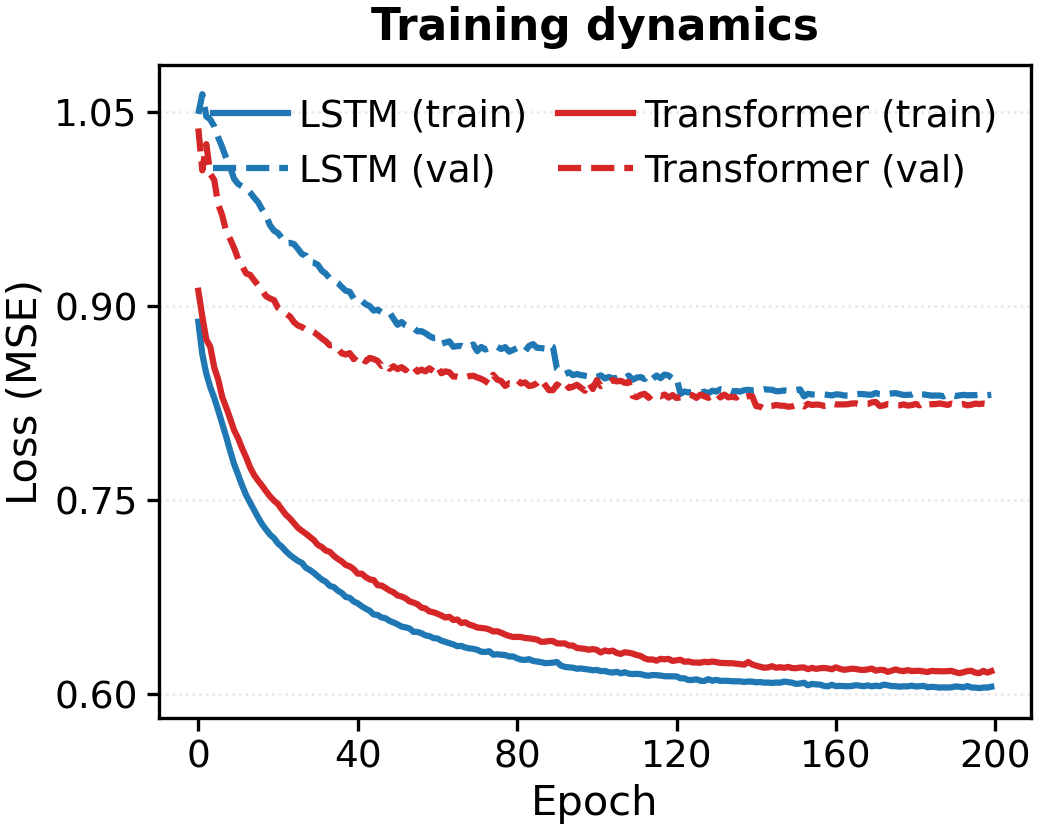

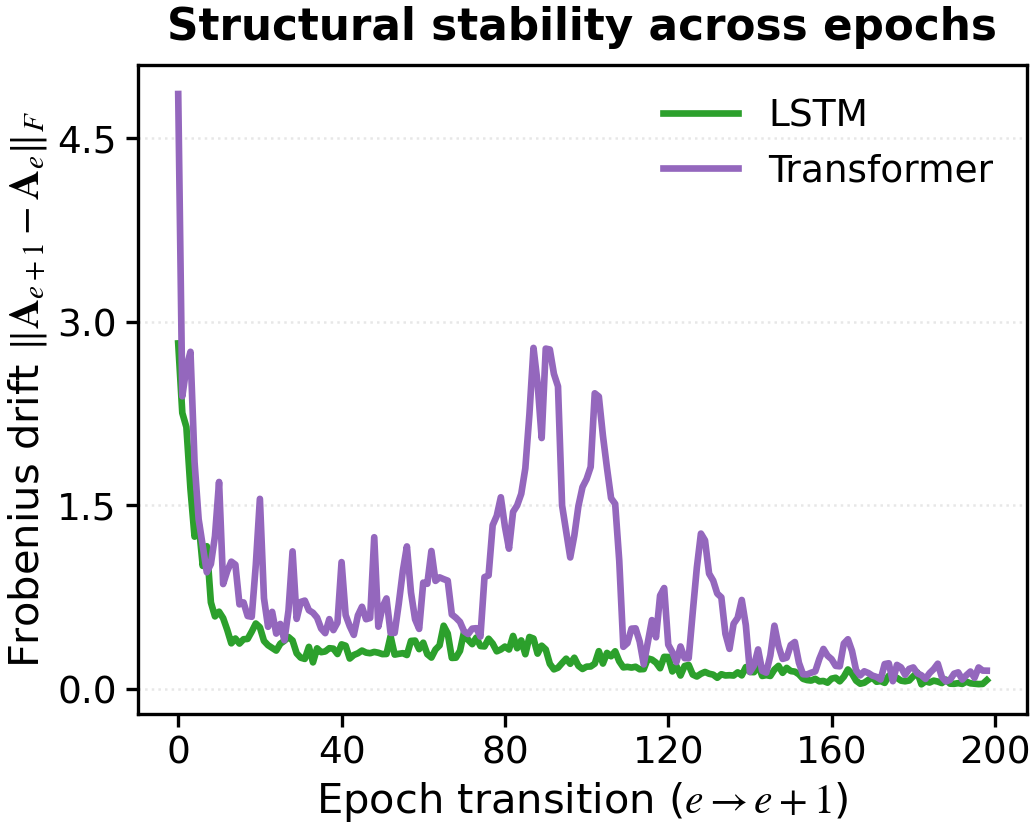

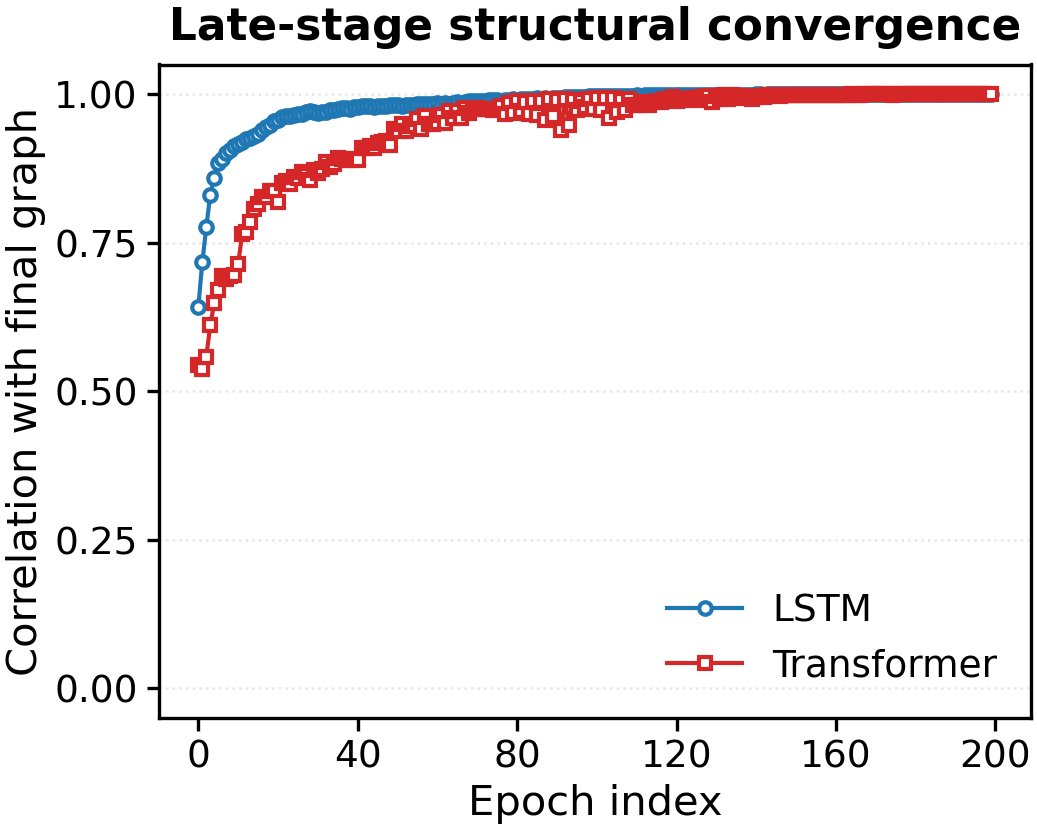

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    'font.size': 9,
    'mathtext.fontset': 'stix',
    'axes.linewidth': 0.8,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.6,
    'ytick.minor.width': 0.6,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'legend.fontsize': 9,
    'legend.frameon': False,
    'grid.alpha': 0.3,
    'grid.linestyle': ':',
    'grid.linewidth': 0.6,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42,  
    'ps.fonttype': 42
})


def load_npy(run_dir, name):
    path = os.path.join(run_dir, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing: {path}")
    return np.load(path, allow_pickle=True)


def vec_upper(A):
    n = A.shape[0]
    iu = np.triu_indices(n, k=1)
    return A[iu]


def safe_corr(x, y):
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    x = x - x.mean()
    y = y - y.mean()
    denom = (np.linalg.norm(x) * np.linalg.norm(y))
    if denom < 1e-12:
        return np.nan
    return float(np.dot(x, y) / denom)


def compute_graph_drift(epoch_graphs):
    E = epoch_graphs.shape[0]
    drifts = []
    for e in range(1, E):
        drifts.append(np.linalg.norm(epoch_graphs[e] - epoch_graphs[e - 1], ord="fro"))
    return np.asarray(drifts, dtype=float)


def compute_lastk_corr(epoch_graphs, last_k=10):
    E = epoch_graphs.shape[0]
    k = min(last_k, E)
    A_ref = epoch_graphs[-1]
    ref_vec = vec_upper(A_ref)
    corrs = []
    idxs = list(range(E - k, E))
    for e in idxs:
        corrs.append(safe_corr(vec_upper(epoch_graphs[e]), ref_vec))
    return np.asarray(idxs, dtype=int), np.asarray(corrs, dtype=float)


def plot_loss_curves(lstm_dir, tr_dir, out_path=None):
    tr_lstm = load_npy(lstm_dir, "train_losses.npy")
    va_lstm = load_npy(lstm_dir, "val_losses.npy")
    tr_tr = load_npy(tr_dir, "train_losses.npy")
    va_tr = load_npy(tr_dir, "val_losses.npy")

    fig, ax = plt.subplots(figsize=(3.5, 2.8))  

    ax.plot(tr_lstm, color='#1f77b4', linestyle='-', linewidth=1.5, label='LSTM (train)')
    ax.plot(va_lstm, color='#1f77b4', linestyle='--', linewidth=1.5, label='LSTM (val)')
    ax.plot(tr_tr,   color='#d62728', linestyle='-', linewidth=1.5, label='Transformer (train)')
    ax.plot(va_tr,   color='#d62728', linestyle='--', linewidth=1.5, label='Transformer (val)')

    ax.set_xlabel('Epoch', labelpad=2)
    ax.set_ylabel('Loss (MSE)', labelpad=2)
    ax.set_title('Training dynamics', pad=6, fontsize=10.5, weight='semibold')
    ax.legend(loc='upper right', ncol=2, columnspacing=0.8, handletextpad=0.3)
    ax.grid(True, which='both', axis='y', alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis='both', which='major', pad=2)

    plt.tight_layout(pad=0.3)
    if out_path:
        plt.savefig(out_path.replace('.png', '.pdf'), format='pdf')
        plt.savefig(out_path, dpi=600)
    plt.show()


def plot_graph_drift(lstm_dir, tr_dir, out_path=None):
    eg_lstm = load_npy(lstm_dir, "epoch_avg_graphs.npy")
    eg_tr = load_npy(tr_dir, "epoch_avg_graphs.npy")

    drift_lstm = compute_graph_drift(eg_lstm)
    drift_tr = compute_graph_drift(eg_tr)

    fig, ax = plt.subplots(figsize=(3.5, 2.8))

    ax.plot(drift_lstm, color='#2ca02c', linestyle='-', linewidth=1.6, label='LSTM')
    ax.plot(drift_tr,   color='#9467bd', linestyle='-', linewidth=1.6, label='Transformer')

    ax.set_xlabel('Epoch transition ($e \\rightarrow e+1$)', labelpad=2)
    ax.set_ylabel(r'Frobenius drift $\| \mathbf{A}_{e+1} - \mathbf{A}_{e} \|_F$', labelpad=2)
    ax.set_title('Structural stability across epochs', pad=6, fontsize=10.5, weight='semibold')
    ax.legend(loc='upper right')
    ax.grid(True, which='both', axis='y', alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis='both', which='major', pad=2)

    plt.tight_layout(pad=0.3)
    if out_path:
        plt.savefig(out_path.replace('.png', '.pdf'), format='pdf')
        plt.savefig(out_path, dpi=600)
    plt.show()


def plot_lastk_stability(lstm_dir, tr_dir, last_k=10, out_path=None):
    eg_lstm = load_npy(lstm_dir, "epoch_avg_graphs.npy")
    eg_tr = load_npy(tr_dir, "epoch_avg_graphs.npy")

    idx_lstm, corr_lstm = compute_lastk_corr(eg_lstm, last_k=last_k)
    idx_tr, corr_tr = compute_lastk_corr(eg_tr, last_k=last_k)

    fig, ax = plt.subplots(figsize=(3.5, 2.8))

    ax.plot(idx_lstm, corr_lstm, color='#1f77b4', marker='o', markersize=3, 
            linestyle='-', linewidth=1, label='LSTM', markerfacecolor='white', markeredgewidth=1)
    ax.plot(idx_tr, corr_tr, color='#d62728', marker='s', markersize=3,
            linestyle='-', linewidth=1, label='Transformer', markerfacecolor='white', markeredgewidth=1)

    ax.set_xlabel('Epoch index', labelpad=2)
    ax.set_ylabel('Correlation with final graph', labelpad=2)
    ax.set_title(f'Late-stage structural convergence', pad=6, fontsize=10.5, weight='semibold')
    ax.legend(loc='lower right')
    ax.grid(True, which='both', axis='y', alpha=0.3)
    ax.set_ylim([-0.05, 1.05])
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis='both', which='major', pad=2)

    plt.tight_layout(pad=0.3)
    if out_path:
        plt.savefig(out_path.replace('.png', '.pdf'), format='pdf')
        plt.savefig(out_path, dpi=600)
    plt.show()


if __name__ == "__main__":
    lstm_dir = "./results/lstm_stage2"
    tr_dir = "./results/transformer_stage2"
    os.makedirs("./results", exist_ok=True)

    plot_loss_curves(lstm_dir, tr_dir, out_path="./results/compare_loss_2.png")

    plot_graph_drift(lstm_dir, tr_dir, out_path="./results/compare_graph_drift_2.png")

    plot_lastk_stability(lstm_dir, tr_dir, last_k=200, out_path="./results/compare_lastk_stability_2.png")